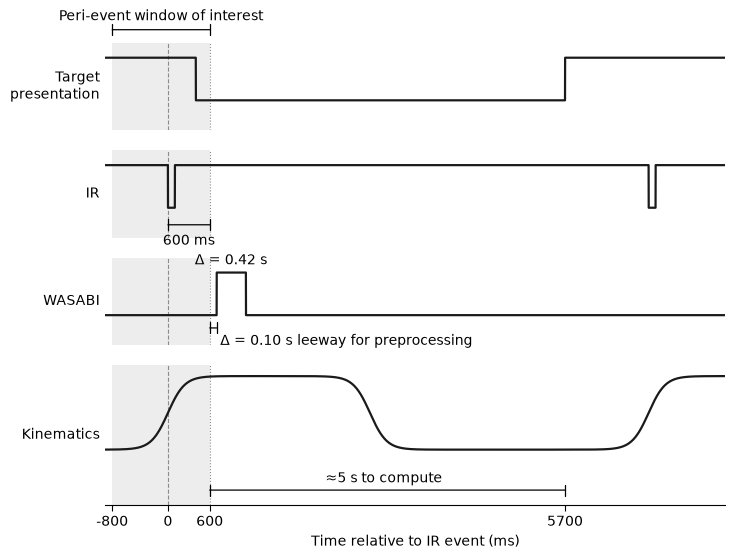

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# Timing parameters in seconds, t = 0 at the IR event
T_TP_ON, T_TP_OFF = -1.2, 0.4
T_IR = 0.0
IR_OFF_DUR = 0.1
WIN_START, WIN_END = -0.8, 0.6
WT_LEEWAY = 0.1
WT_DUR = 0.42
SPAN = 5.0
T_START, T_END = -0.9, 8

wt_on = WIN_END + WT_LEEWAY
wt_off = wt_on + WT_DUR
tp_off = T_TP_OFF
next_tp_on = wt_on + SPAN
next_ir = next_tp_on + (T_IR - T_TP_ON)

t = np.linspace(T_START, T_END, 5000)


def pulse(on, off):
    return ((t >= on) & (t < off)).astype(float)


def sig(t0, tau):
    return 1 / (1 + np.exp(-(t - t0) / tau))


tp = pulse(T_TP_ON, tp_off) + pulse(next_tp_on, np.inf)
ir = 1 - pulse(T_IR, T_IR + IR_OFF_DUR) - pulse(next_ir, next_ir + IR_OFF_DUR)
wt = pulse(wt_on, wt_off)
kin = sig(T_IR, 0.12) - sig(2.9, 0.12) + sig(next_ir, 0.12)

plt.rcParams.update({"font.size": 10, "font.family": "sans-serif"})
fig, axes = plt.subplots(
    4, 1, sharex=True, figsize=(8, 6),
    gridspec_kw=dict(height_ratios=[1, 1, 1, 1.6], hspace=0.2),
)
signals = [(tp, "Target\npresentation"), (ir, "IR"), (wt, "WASABI"), (kin, "Kinematics")]
color = "0.1"
bracket = dict(arrowstyle="|-|", lw=0.9, mutation_scale=4, shrinkA=0, shrinkB=0)

for ax, (y, label) in zip(axes, signals):
    ax.plot(t, y, color=color, lw=1.6)
    ax.set_ylabel(label, rotation=0, ha="right", va="center")
    ax.set_yticks([])
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_visible(False)
    ax.tick_params(axis="x", length=0)
    ax.axvspan(WIN_START, WIN_END, color="0.93", lw=0, zorder=-1)
    ax.axvline(T_IR, ls="--", lw=0.8, color="0.55", zorder=0)
    ax.axvline(WIN_END, ls=":", lw=0.8, color="0.55", zorder=0)
    ax.axvline(T_TP_ON, ls=":", lw=0.8, color="0.55", zorder=0)

for ax in axes[:3]:
    ax.set_ylim(-0.7, 1.35)

# Peri-event window label above the top row
ax = axes[0]
ax.annotate("", xy=(WIN_START, 1.15), xytext=(WIN_END, 1.15), xycoords=("data", "axes fraction"),
            textcoords=("data", "axes fraction"), arrowprops=bracket, annotation_clip=False)
ax.text((WIN_START + WIN_END) / 2, 1.22, "Peri-event window of interest", ha="center", va="bottom",
        transform=ax.get_xaxis_transform())
fig.subplots_adjust(top=0.88)

# IR to end of window
ax = axes[1]
ax.annotate("", xy=(T_IR, -0.4), xytext=(WIN_END, -0.4), arrowprops=bracket)
ax.text((T_IR + WIN_END) / 2, -0.62, f"{(WIN_END - T_IR) * 1000:.0f} ms", ha="center", va="top")

# WASABI leeway and duration labels
ax = axes[2]
ax.annotate("", xy=(WIN_END, -0.3), xytext=(wt_on, -0.3), arrowprops=bracket)
ax.text(wt_on + 0.05, -0.45, rf"$\Delta$ = {WT_LEEWAY:.2f} s leeway for preprocessing", ha="left", va="top")
ax.text((wt_on + wt_off) / 2, 1.1, rf"$\Delta$ = {WT_DUR:.2f} s", ha="center", va="bottom")

# Span arrow under kinematics
ax = axes[3]
ax.set_ylim(-0.75, 1.15)
ax.annotate("", xy=(WIN_END, -0.55), xytext=(wt_on + SPAN, -0.55), arrowprops=bracket)
ax.text(WIN_END + SPAN / 2, -0.49, f"≈{SPAN:g} s to compute", ha="center", va="bottom")

ax.spines["bottom"].set_visible(True)
ax.tick_params(axis="x", length=4)
ax.set_xticks([WIN_START, T_TP_ON, T_IR, WIN_END, next_tp_on])
ax.set_xticklabels([f"{x * 1000:.0f}" for x in ax.get_xticks()])
ax.set_xlim(T_START, T_END)
ax.set_xlabel("Time relative to IR event (ms)")

fig.savefig("task_timing.svg", bbox_inches="tight")
plt.show()